Connected to .venv01 (3.13.11) (Python 3.13.11)

In [ ]:
# ANALYSIS GRU
# SEARCH WORDS :
# YEARLY_GRU_ESTIMATION
# TESTING_MAIN_WITH_CACHE
# GRU_TRADER_DIAGNOSTICS
# GRU_FITTED_TARGET_SPACE_PERFORMANCE
# GRU_TARGET_PERFORMANCE_EXECUTED_VS_SKIPPED
# GRU_SCORE_CALIBRATION_DIAGNOSTIC
# GRU_SCORE_THRESHOLD_CALIBRATION
# GRU_SCORE_THRESHOLD_TRADER_CALIBRATION


import pandas as pd
import numpy as np
import warnings
import os, sys
import pickle

from pathlib import Path
from arch.utility.exceptions import ConvergenceWarning

In [ ]:
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)


sys.path.insert(0, "/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")
sys.path.insert(0, "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/MFIV_calibration")
os.chdir("/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")
sys.modules.pop("srcB", None)

In [ ]:
# =============================================================================================================
# ======================================= LOAD BASE OUTPUTS ===================================================
# =============================================================================================================
# Starts from the completed MFIV TCN output file.

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/outputs_by_year/outputs_by_year_04.pkl", "rb") as f:
    outputs_by_year = pickle.load(f)

In [ ]:
# =============================================================================================================
# ======================================= IMPORTS FROM SRC ====================================================
# =============================================================================================================

from srcB.market import *
from srcB.helpers import *

In [ ]:
# =============================================================================================================
# ======================================= READ D_BTC AND DF ===================================================
# =============================================================================================================

DATA_DIR = Path("../data/rawData")

YEARS = [2019, 2020, 2021]
QUARTERS = ["q1", "q2", "q3", "q4"]

d_btc_raw_by_year = {}
df_raw_by_year = {}

for y in YEARS:
    d_btc_raw_by_year[y] = pd.read_parquet(DATA_DIR / f"btc_underlying_minutely_{y}.parquet")
    df_raw_by_year[y] = pd.read_parquet(DATA_DIR / f"derivative_data_{y}.parquet")

In [ ]:
# =============================================================================================================
# ======================================= SET INDEX TO DATETIME ===============================================
# =============================================================================================================

for y in YEARS:
    d_btc_raw_by_year[y] = d_btc_raw_by_year[y].set_index(
        pd.to_datetime(d_btc_raw_by_year[y]["date_time"])
    )
    df_raw_by_year[y] = df_raw_by_year[y].set_index(
        pd.to_datetime(df_raw_by_year[y]["date_time"])
    )

In [ ]:
# =============================================================================================================
# ======================================= LOAD XQ_BY_YEAR USING X_BY_YEAR =====================================
# =============================================================================================================

with open(
    "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/x_by_year_fut/x_by_year.pkl",
    "rb"
) as f:
    X_by_year = pd.read_pickle(f)

for y in YEARS:
    X_by_year[y] = X_by_year[y].copy()
    X_by_year[y]["rv"] = X_by_year[y]["rt"] ** 2

Xq_by_year = {}

for y in YEARS:
    Xq_by_year[y] = {}

    Xq_by_year[y]["q1"] = X_by_year[y].loc[
        f"{y}-01-01" : f"{y}-03-31 23:59:59"
    ].copy()

    Xq_by_year[y]["q2"] = X_by_year[y].loc[
        f"{y}-04-01" : f"{y}-06-30 23:59:59"
    ].copy()

    Xq_by_year[y]["q3"] = X_by_year[y].loc[
        f"{y}-07-01" : f"{y}-09-30 23:59:59"
    ].copy()

    Xq_by_year[y]["q4"] = X_by_year[y].loc[
        f"{y}-10-01" : f"{y}-12-31 23:59:59"
    ].copy()

In [ ]:
# =============================================================================================================
# ======================================= MFIV SCALING ========================================================
# ================== CONVERT ANNUALIZED MFIV -> CUMULATIVE H-HOUR DECIMAL VARIANCE ==========================
# =============================================================================================================

MFIVS = list(range(2, 577))

for y in YEARS:
    for q in QUARTERS:
        for H in MFIVS:
            Xq_by_year[y][q][f"MFIV_{H}"] *= H / 8760.0

In [ ]:
# =============================================================================================================
# ======================================= BORROW RFR COLUMN ===================================================
# =============================================================================================================

with open(
    "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/ready_data/d_btc_by_year_all.pkl",
    "rb"
) as f:
    d_btc_by_year = pickle.load(f)

for y in YEARS:
    d_btc_raw_by_year[y]["rfr"] = d_btc_by_year[y]["rfr"].reindex(
        d_btc_raw_by_year[y].index,
        method="ffill"
    )

In [ ]:
# =============================================================================================================
# ======================================= LOAD GRU PARAMETERS =================================================
# =============================================================================================================

with open(
    "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/hyperparameters/gru_best_params.pkl","rb") as f:
    best_gru_params = pickle.load(f)

SEED = 11

In [ ]:
# =============================================================================================================
# ======================================= YEARLY_GRU_ESTIMATION ===============================================
# =============================================================================================================

sys.modules.pop("srcB.gru_model_mfiv", None)
from srcB.gru_model_mfiv import *

gru_bundle_by_year = {}
gru_targets_by_year = {}
gru_output_by_year = {}

for y in YEARS:
    X_df = pd.concat([
        Xq_by_year[y][q]
        for q in QUARTERS
    ]).sort_index().copy()

    garch_df = pd.concat([
        outputs_by_year[y][q]["garch"]
        for q in QUARTERS
    ]).sort_index()

    X_df["garch"] = garch_df.reindex(X_df.index)

    gru_output, gru_bundle, gru_targets = gru_mfiv(
        X_df=X_df,
        option_df=df_raw_by_year[y],
        time_df=d_btc_raw_by_year[y],
        sequence_length=168,
        forward_hours=24,
        delta_target=0.20,
        hidden_size=best_gru_params["hidden_size"],
        num_layers=best_gru_params["num_layers"],
        dropout=best_gru_params["dropout"],
        epochs=best_gru_params["epochs_by_year"][y],
        batch_size=best_gru_params["batch_size"],
        learning_rate=best_gru_params["learning_rate"],
        weight_decay=best_gru_params["weight_decay"],
        seed=SEED
    )

    gru_output_by_year[y] = gru_output
    gru_bundle_by_year[y] = gru_bundle
    gru_targets_by_year[y] = gru_targets

    for q in QUARTERS:
        q_index = Xq_by_year[y][q].index
        gru_q = gru_output.reindex(q_index)
        outputs_by_year[y][q] = pd.concat([outputs_by_year[y][q],gru_q], axis=1)

In [ ]:
# =============================================================================================================
# ======================================= SAVE GRU BUNDLES ====================================================
# =============================================================================================================

os.makedirs("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/GRU",exist_ok=True)

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/GRU/gru_bundle_by_year.pkl","wb") as f:
    pickle.dump(gru_bundle_by_year, f)

print("GRU bundles saved:", list(gru_bundle_by_year.keys()))

GRU bundles saved: [2019, 2020, 2021]


In [ ]:
# =============================================================================================================
# ======================================= SAVE OUTPUTS ========================================================
# =============================================================================================================
# Save before the runtime trader adapter so the real TCN columns remain untouched in the cumulative file.

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/outputs_by_year/outputs_by_year_05.pkl","wb") as f:
    pickle.dump(outputs_by_year, f)

In [ ]:
# =============================================================================================================
# ======================================= PREPARE TRADER INPUT ================================================
# =============================================================================================================

for y in YEARS:
    for q in QUARTERS:
        outputs_by_year[y][q]["rv"] = Xq_by_year[y][q]["rv"].reindex(
            outputs_by_year[y][q].index
        )

        outputs_by_year[y][q]["MFIV_24"] = Xq_by_year[y][q]["MFIV_24"].reindex(
            outputs_by_year[y][q].index
        )

In [ ]:
# =============================================================================================================
# ======================================= GRU TRADER ADAPTER ==================================================
# =============================================================================================================
# GRU signals are not altered. The existing trader reads the TCN interface names,
# so only the action and score columns are copied for this runtime trader pass.

for y in YEARS:
    for q in QUARTERS:
        outputs_by_year[y][q]["tcn_action"] = outputs_by_year[y][q]["gru_action"]
        outputs_by_year[y][q]["tcn_best_score"] = outputs_by_year[y][q]["gru_best_score"]

In [ ]:
# =============================================================================================================
# ======================================= CACHE FOR WARMUP ====================================================
# =============================================================================================================

CACHE_YEARS = [2019, 2020, 2021]
RUN_BY = "year"

if RUN_BY == "year":
    trader_cache = {
        y: pd.concat(
            [
                outputs_by_year[yy][q]
                for yy in CACHE_YEARS
                if yy <= y
                for q in QUARTERS
            ]
        ).sort_index()
        for y in CACHE_YEARS
    }

elif RUN_BY == "quarter":
    trader_cache = {
        (y, q): pd.concat(
            [
                outputs_by_year[yy][qq]
                for yy in CACHE_YEARS
                for qq in QUARTERS
                if (
                    yy < y
                    or (yy == y and QUARTERS.index(qq) <= QUARTERS.index(q))
                )
            ]
        ).sort_index()
        for y in CACHE_YEARS
        for q in QUARTERS
    }

if RUN_BY == "year":
    PERIODS = YEARS
else:
    PERIODS = [(y, q) for y in YEARS for q in QUARTERS]

In [ ]:
# =============================================================================================================
# ======================================= TESTING_MAIN_WITH_CACHE =============================================
# =============================================================================================================

sys.modules.pop("srcB.trader_testing_tcn", None)
from srcB.trader_testing_tcn import testing_execute_trading_strategy

MODEL = "gru"
RUN_BY = "year"
strategy_results = {}

for YEAR in YEARS:

    market = Market(
        option_df=df_raw_by_year[YEAR],
        time_df=d_btc_raw_by_year[YEAR],
        starting_cash=100_000,
        im_multiplier=0.15,
        mm_buffer_rate=0.05,
    )

    greek_tests = []
    yearly_snapshots = []

    if RUN_BY == "year":
        periods = [None]
    else:
        periods = ["q1", "q2", "q3", "q4"]

    for q in periods:
        snapshots, greek_tests_q = testing_execute_trading_strategy(
            bt_year=YEAR,
            bt_quarter=q,
            model="tcn_mfiv",
            outputs_by_year=outputs_by_year,
            market=market,
            trader_cache=trader_cache,
            run_by=RUN_BY,
            quantity=10,
            expiry_days=30,
            hold_days=7,
            lookback_hours=168,
            mean_hours=12,
            ql=0.10,
            qh=0.90,
            z=1.645
        )

        greek_tests.extend(greek_tests_q)
        yearly_snapshots.extend(snapshots)

    # Guard for 0 transactions in a year
    if len(market.transactions) == 0:
        raise RuntimeError(f"GRU main IS trader produced zero transactions in {YEAR}, go to section TESTING_MAIN_WITH_CACHE")
    
    history_key = f"{MODEL}_{str(YEAR)[2:]}"
    equity_curve = market.get_equity_history()

    strategy_results[history_key] = {
        "equity_curve": equity_curve,
        "snapshots": yearly_snapshots,
        "greek_tests": greek_tests,
        "orders": list(market.orders),
        "transactions": list(market.transactions),
        "final_cash": market.cash,
        "required_margin": market.get_total_required_margin(),
        "free_liquidity": market.get_free_liquidity(),
    }

print(YEAR, MODEL)

2021 gru


In [ ]:
# =============================================================================================================
# ======================================= BASIC CHECKS ========================================================
# =============================================================================================================

print(len(greek_tests))
print(greek_tests[:1])
print(pd.Series([x["action"] for x in market.transactions]).value_counts())
print("outputs:", "gru_action" in outputs_by_year[2019]["q1"].columns)
print("adapter:", "tcn_action" in outputs_by_year[2019]["q1"].columns)
print("cache:", "tcn_action" in trader_cache[2019].columns)
[c for c in trader_cache[2019].columns if c.startswith("gru")]

258
[{'time': Timestamp('2021-01-13 01:00:00+0000', tz='UTC'), 'tcn_action': 'short_strangle', 'tcn_best_score': 0.002200343646109104, 'signal': nan, 'q_lo': nan, 'selected_calls': [<srcB.market.Instrument object at 0x16319f450>], 'selected_puts': [<srcB.market.Instrument object at 0x16319dd50>], 'call_ivs': [148.27], 'put_ivs': [180.62], 'spot': 32649.5, 'rfr': 0.0008997975607295042, 'call_greeks': [{'delta': -0.1990149650291837, 'gamma': np.float64(-7.87193720955338e-05)}], 'put_greeks': [{'delta': 0.1098424940988354, 'gamma': np.float64(-4.3486472934061565e-05)}], 'entry_equity': np.float64(100788.6696758897)}]
sell_to_open         390
buy_to_close         284
expiry_settlement    141
buy_to_open          126
sell_to_close         91
Name: count, dtype: int64
outputs: True
adapter: True
cache: True


['gru_long_straddle',
 'gru_short_straddle',
 'gru_long_strangle',
 'gru_short_strangle',
 'gru_best_score',
 'gru_action']

In [ ]:
# =============================================================================================================
# ======================================= SAVE STRATEGY RESULTS ===============================================
# =============================================================================================================

os.makedirs(
    "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/data_strategy_results",
    exist_ok=True
)

with open(
    "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/data_strategy_results/strategy_results_gru.pkl",
    "wb"
) as f:
    pickle.dump(strategy_results, f)

In [ ]:
# =============================================================================================================
# ======================================= SHARPE ===============================================================
# =============================================================================================================

rows = []

for y in YEARS:
    history_key = f"gru_{str(y)[2:]}"
    snapshots = strategy_results[history_key]["snapshots"]

    equity = pd.Series(
        [s["equity"] for s in snapshots],
        index=[s["time"] for s in snapshots]
    )

    returns = equity.pct_change().dropna()
    sharpe = returns.mean() / returns.std() * np.sqrt(24 * 365)

    rows.append({
        "year": y,
        "model": "gru",
        "sharpe": sharpe
    })

sharpe_table = pd.DataFrame(rows)
print(sharpe_table)

   year model    sharpe
0  2019   gru  0.243651
1  2020   gru  0.198770
2  2021   gru  0.866025


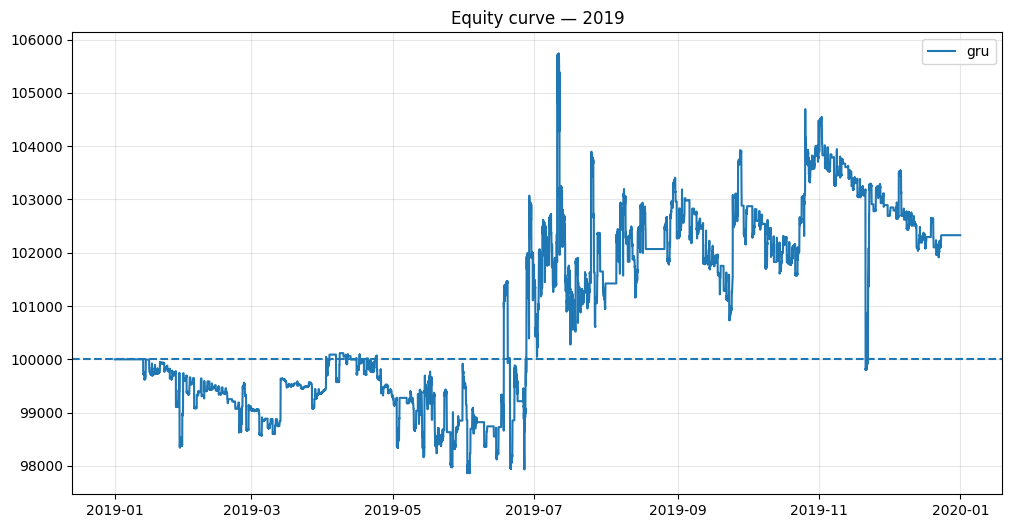

In [ ]:
# =============================================================================================================
# ======================================= PLOT EQUITY ==========================================================
# =============================================================================================================

import matplotlib.pyplot as plt

PLOT_YEAR = 2019
plot_key = f"gru_{str(PLOT_YEAR)[2:]}"
result = strategy_results[plot_key]
eq = pd.DataFrame(result["snapshots"]).drop_duplicates("time").sort_values("time")

plt.figure(figsize=(12, 6))
plt.plot(eq["time"], eq["equity"], label="gru")
plt.axhline(100_000, linestyle="--")
plt.title(f"Equity curve — {PLOT_YEAR}")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [ ]:
# =============================================================================================================
# ======================================= GRU SPECIFIC (TRADER DIAGNOSTICS) ==================================
# =============================================================================================================
# Reconstruct the actual executed GRU option positions from the trader transaction log.

MODEL = "gru"
all_trades = []

for y in YEARS:
    tx = pd.DataFrame(
        strategy_results[f"{MODEL}_{str(y)[2:]}"]["transactions"]
    ).sort_values("time")

    open_actions = {"buy_to_open", "sell_to_open"}
    close_actions = {"buy_to_close", "sell_to_close", "liquidate", "expiry_settlement"}

    trades = []
    open_pos = {}

    for _, r in tx.iterrows():
        sym = r["symbol"]

        if r["action"] in open_actions:
            open_pos[sym] = {
                "entry_time": r["time"],
                "right": r["right"],
                "strike": r["strike"],
                "direction": r["held_direction"],
                "pnl": float(r["cash_change"])
            }

        elif r["action"] in close_actions and sym in open_pos:
            open_pos[sym]["pnl"] += float(r["cash_change"])
            open_pos[sym]["exit_time"] = r["time"]
            trades.append({
                "symbol": sym,
                **open_pos.pop(sym)
            })

    legs = pd.DataFrame(trades)

    for entry_time, g in legs.groupby("entry_time"):
        direction = "short" if (g["direction"] == "sell").all() else "long"
        structure = "straddle" if g["strike"].nunique() == 1 else "strangle"
        side = f"{direction}_{structure}"

        call_pnl = g.loc[g["right"] == "C", "pnl"].sum()
        put_pnl = g.loc[g["right"] == "P", "pnl"].sum()
        total_pnl = call_pnl + put_pnl

        all_trades.append({
            "year": y,
            "entry": entry_time,
            "exit": g["exit_time"].max(),
            "side": side,
            "call_pnl": call_pnl,
            "put_pnl": put_pnl,
            "total_pnl": total_pnl,
            "position_result": "PROFIT" if total_pnl > 0 else "LOSS"
        })

gru_trades = pd.DataFrame(all_trades)
print(gru_trades.to_string(index=False))

summary = (
    gru_trades.groupby(["year", "side"])
    .agg(
        positions=("total_pnl", "size"),
        profitable=("total_pnl", lambda x: (x > 0).sum()),
        losing=("total_pnl", lambda x: (x < 0).sum()),
        total_pnl=("total_pnl", "sum"),
        avg_pnl=("total_pnl", "mean")
    )
    .reset_index()
)

print("\nSUMMARY")
print(summary.to_string(index=False))

 year                     entry                      exit           side     call_pnl      put_pnl    total_pnl position_result
 2019 2019-01-13 07:00:00+00:00 2019-01-14 09:00:00+00:00  long_straddle   -44.206635    39.167470    -5.039165            LOSS
 2019 2019-01-15 21:00:00+00:00 2019-01-17 02:00:00+00:00  long_straddle   -21.659675   -49.966455   -71.626130            LOSS
 2019 2019-01-17 03:00:00+00:00 2019-01-18 09:00:00+00:00  long_straddle     5.741975   -33.401265   -27.659290            LOSS
 2019 2019-01-18 10:00:00+00:00 2019-01-19 10:00:00+00:00  long_straddle    29.582100   -92.399770   -62.817670            LOSS
 2019 2019-01-19 11:00:00+00:00 2019-01-22 06:00:00+00:00  long_straddle   -25.132710   118.544645    93.411935          PROFIT
 2019 2019-01-22 10:00:00+00:00 2019-01-23 14:00:00+00:00  long_straddle    -2.806685   -42.000155   -44.806840            LOSS
 2019 2019-01-23 18:00:00+00:00 2019-01-24 18:00:00+00:00  long_straddle   -29.264685   -25.366330   -54

In [ ]:
# =============================================================================================================
# ================================ GRU FITTED TARGET-SPACE PERFORMANCE ========================================
# =============================================================================================================
# Target-space Sharpe here is mean/std and is not annualized.

target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]

rows = []

for y in YEARS:
    test = pd.concat([
        gru_output_by_year[y][["gru_action"]],
        gru_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    realized = pd.Series(0.0, index=test.index)

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        mask = test["gru_action"] == action
        realized.loc[mask] = test.loc[mask, f"target_{action}"]

    sharpe = realized.mean() / realized.std()

    rows.append({
        "year": y,
        "n": len(realized),
        "mean_target": realized.mean(),
        "target_sharpe": sharpe,
        "profitable": (realized > 0).mean()
    })

target_sharpe = pd.DataFrame(rows)
print(target_sharpe)

   year     n  mean_target  target_sharpe  profitable
0  2019  2194     0.001215       0.043971    0.280310
1  2020  4093     0.002702       0.100518    0.444662
2  2021  5008     0.003013       0.129365    0.490815


In [ ]:
# =============================================================================================================
# ================================ GRU TARGET PERFORMANCE: EXECUTED VS SKIPPED ================================
# =============================================================================================================
# Question: does the sequential trader execute a representative subset of the GRU's fitted opportunities?

target_cols = [
    "target_long_straddle",
    "target_short_straddle",
    "target_long_strangle",
    "target_short_strangle"
]

rows = []

for y in YEARS:

    test = pd.concat([
        gru_output_by_year[y][["gru_action"]],
        gru_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    test = test[test["gru_action"] != "no_trade"].copy()
    test["target_pnl"] = 0.0

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["gru_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]

    entries = pd.DataFrame(
        strategy_results[f"gru_{str(y)[2:]}"]["greek_tests"]
    )

    entries["time"] = pd.to_datetime(entries["time"], utc=True).dt.floor("h")
    entries = entries.drop_duplicates("time")

    covered = entries[entries["time"].isin(test.index)].copy()

    predicted = test["gru_action"].reindex(covered["time"]).to_numpy()
    action_match = (predicted == covered["tcn_action"].to_numpy()).mean()

    executed = test[test.index.isin(covered["time"])]
    skipped = test[~test.index.isin(covered["time"])]

    rows.append({
        "year": y,
        "signals": len(test),
        "successful_entries": len(entries),
        "entries_with_target": len(covered),
        "target_coverage": len(covered) / len(entries) if len(entries) else np.nan,
        "action_match": action_match,
        "all_sharpe": test["target_pnl"].mean() / test["target_pnl"].std(),
        "executed_sharpe": executed["target_pnl"].mean() / executed["target_pnl"].std(),
        "skipped_sharpe": skipped["target_pnl"].mean() / skipped["target_pnl"].std()
    })

execution_check = pd.DataFrame(rows)
print(execution_check)

   year  signals  successful_entries  entries_with_target  target_coverage  \
0  2019     1440                 190                   86         0.452632   
1  2020     3348                 253                  170         0.671937   
2  2021     3930                 258                  190         0.736434   

   action_match  all_sharpe  executed_sharpe  skipped_sharpe  
0           1.0    0.054296         0.058882        0.053979  
1           1.0    0.111262         0.064667        0.113230  
2           1.0    0.146366         0.155420        0.145907  


In [ ]:
# =============================================================================================================
# ======================================= GRU SCORE CALIBRATION DIAGNOSTIC ===================================
# =============================================================================================================
# Question: are higher GRU score bins associated with better realized target outcomes?

rows = []

for y in YEARS:
    test = pd.concat([
        gru_output_by_year[y][["gru_action", "gru_best_score"]],
        gru_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    test = test[test["gru_action"] != "no_trade"].copy()
    test["target_pnl"] = 0.0

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = test["gru_action"] == action
        test.loc[m, "target_pnl"] = test.loc[m, f"target_{action}"]

    test["score_bin"] = pd.qcut(
        test["gru_best_score"],
        5,
        labels=False,
        duplicates="drop"
    )

    x = (
        test.groupby("score_bin")
        .agg(
            n=("target_pnl", "size"),
            mean_score=("gru_best_score", "mean"),
            mean_target=("target_pnl", "mean"),
            sharpe=("target_pnl", lambda z: z.mean() / z.std()),
            profitable=("target_pnl", lambda z: (z > 0).mean())
        )
        .reset_index()
    )

    x["year"] = y
    rows.append(x)

score_check = pd.concat(rows, ignore_index=True)

print(score_check[[
    "year", "score_bin", "n", "mean_score",
    "mean_target", "sharpe", "profitable"
]].to_string(index=False))

 year  score_bin   n  mean_score  mean_target    sharpe  profitable
 2019          0 288    0.000596     0.000240  0.009655    0.458333
 2019          1 288    0.001624     0.000071  0.002147    0.493056
 2019          2 288    0.002340    -0.001966 -0.053760    0.454861
 2019          3 288    0.003119     0.009319  0.241497    0.427083
 2019          4 288    0.003885     0.001595  0.045808    0.302083
 2020          0 670    0.000751     0.000197  0.011576    0.534328
 2020          1 669    0.002092     0.002759  0.108907    0.597907
 2020          2 670    0.003505     0.002377  0.125777    0.614925
 2020          3 669    0.004859     0.001128  0.058311    0.529148
 2020          4 670    0.006811     0.010051  0.193854    0.441791
 2021          0 786    0.000489     0.001158  0.061917    0.634860
 2021          1 786    0.001487     0.000430  0.021468    0.622137
 2021          2 786    0.002682     0.003327  0.128911    0.610687
 2021          3 786    0.004522     0.004076  0

In [ ]:
# =============================================================================================================
# ======================================= GRU SCORE THRESHOLD CALIBRATION ====================================
# =============================================================================================================
# Question: if only signals with gru_best_score >= threshold are retained, does fitted target performance improve?

tests = {}

for y in YEARS:

    x = pd.concat([
        gru_output_by_year[y][["gru_action", "gru_best_score"]],
        gru_targets_by_year[y][target_cols]
    ], axis=1, sort=False).dropna()

    x = x[x["gru_action"] != "no_trade"].copy()
    x["target_pnl"] = 0.0

    for action in ["long_straddle", "short_straddle", "long_strangle", "short_strangle"]:
        m = x["gru_action"] == action
        x.loc[m, "target_pnl"] = x.loc[m, f"target_{action}"]

    tests[y] = x

scores_all = pd.concat([
    tests[y]["gru_best_score"]
    for y in YEARS
])

rows = []

for q in [0, .20, .40, .50, .60, .70, .80, .85, .90]:

    threshold = scores_all.quantile(q)

    for y in YEARS:

        x = tests[y][tests[y]["gru_best_score"] >= threshold]
        sharpe = x["target_pnl"].mean() / x["target_pnl"].std()

        rows.append({
            "quantile": q,
            "threshold": threshold,
            "year": y,
            "n": len(x),
            "mean_target": x["target_pnl"].mean(),
            "sharpe": sharpe
        })

threshold_check = pd.DataFrame(rows)
print(threshold_check.to_string(index=False))

 quantile    threshold  year    n  mean_target   sharpe
     0.00 1.364388e-07  2019 1440     0.001852 0.054296
     0.00 1.364388e-07  2020 3348     0.003303 0.111262
     0.00 1.364388e-07  2021 3930     0.003839 0.146366
     0.20 1.172909e-03  2019 1167     0.002278 0.063381
     0.20 1.172909e-03  2020 2804     0.003915 0.124117
     0.20 1.172909e-03  2021 3003     0.004733 0.167766
     0.40 2.244156e-03  2019  752     0.004291 0.117737
     0.40 2.244156e-03  2020 2269     0.004215 0.127874
     0.40 2.244156e-03  2021 2210     0.005976 0.199143
     0.50 2.878245e-03  2019  538     0.005479 0.146728
     0.50 2.878245e-03  2020 1973     0.004483 0.131074
     0.50 2.878245e-03  2021 1848     0.006783 0.219623
     0.60 3.501228e-03  2019  262     0.001059 0.031402
     0.60 3.501228e-03  2020 1680     0.004843 0.134011
     0.60 3.501228e-03  2021 1545     0.007187 0.227519
     0.70 4.266448e-03  2019   35     0.012271 0.249906
     0.70 4.266448e-03  2020 1314     0.005703 0

In [ ]:
# =============================================================================================================
# ================================ GRU SCORE THRESHOLD TRADER CALIBRATION =====================================
# =============================================================================================================
# Question: does score filtering improve the actual sequential trader?
# Same five-candidate search budget as the TCN: baseline + pooled 70/80/85/90 percentiles.

THRESHOLDS = [
    0.0,
    float(scores_all.quantile(.70)),
    float(scores_all.quantile(.80)),
    float(scores_all.quantile(.85)),
    float(scores_all.quantile(.90))
]

rows = []

for threshold in THRESHOLDS:
    for y in YEARS:

        market = Market(
            option_df=df_raw_by_year[y],
            time_df=d_btc_raw_by_year[y],
            starting_cash=100_000,
            im_multiplier=0.15,
            mm_buffer_rate=0.05,
        )

        snapshots, greek_tests = testing_execute_trading_strategy(
            bt_year=y,
            bt_quarter=None,
            model="tcn_mfiv",
            outputs_by_year=outputs_by_year,
            market=market,
            trader_cache=trader_cache,
            run_by="year",
            tcn_score_threshold=threshold
        )

        equity = pd.Series(
            [s["equity"] for s in snapshots],
            index=[s["time"] for s in snapshots]
        )

        returns = equity.pct_change().dropna()
        sharpe = returns.mean() / returns.std() * np.sqrt(24 * 365)

        rows.append({
            "threshold": threshold,
            "year": y,
            "trades": len(greek_tests),
            "sharpe": sharpe
        })

threshold_trader_check = pd.DataFrame(rows)
print(threshold_trader_check.to_string(index=False))

 threshold  year  trades   sharpe
  0.000000  2019     190 0.243651
  0.000000  2020     253 0.198770
  0.000000  2021     258 0.866025
  0.004266  2019      11 0.534685
  0.004266  2020     133 0.769162
  0.004266  2021     122 0.752612
  0.005197  2019       0      NaN
  0.005197  2020      86 0.417109
  0.005197  2021     100 0.948227
  0.005824  2019       0      NaN
  0.005824  2020      61 0.473512
  0.005824  2021      77 0.690872
  0.006639  2019       0      NaN
  0.006639  2020      29 0.488795
  0.006639  2021      58 0.730396
